In [23]:
import numpy as np
import pandas as pd

# 1. Store raw data in NumPy arrays
dates = np.array(["2026-10-01", "2026-10-02", "2026-10-03", "2026-10-04", "2026-10-05", "2026-10-06", "2026-10-07"])
temps = np.array([31, 33, 36, 32, 35.5, 30, 34])

hottest_idx = np.argmax(temps)
coldest_idx = np.argmin(temps)

print(f"hottest: {dates[hottest_idx]} temp: {temps[hottest_idx]}")
print(f"coldest: {dates[coldest_idx]} temp: {temps[coldest_idx]}")

avg_temp = np.mean(temps)
print(f"avg = {avg_temp}")

mask = temps > 35
above_35_date = dates[mask]
above_35_temp = temps[mask]

for date, temp in zip(above_35_date, above_35_temp):
  print(f"{date}: {temp}")

hottest: 2026-10-03 temp: 36.0
coldest: 2026-10-06 temp: 30.0
avg = 33.07142857142857
2026-10-03: 36.0
2026-10-05: 35.5


In [24]:
import pandas as pd

# Load dataset into a Pandas DataFrame
df = pd.read_csv("Titanic-Dataset.csv")

# View the first 5 rows
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [25]:
from google.colab import drive
import pandas as pd

# 1. Mount your Google Drive
drive.mount('/content/drive')

# 2. Update the path below to match where Titanic-Dataset.csv is located in your Drive
# Example if it's in your root Drive folder:
df = pd.read_csv('/content/drive/MyDrive/Titanic-Dataset.csv')

# 3. View the first 5 rows
df.head()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [26]:
# Decision Tree Classifier

import pandas as pd

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load dataset
data = load_breast_cancer(as_frame=True)

X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define impurity criteria
criteria = ["entropy", "log_loss", "gini"]

# 4. Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# 5. Train and evaluate each model
for criterion in criteria:

    model = Pipeline([
        ("classifier", DecisionTreeClassifier(
            criterion=criterion,
            random_state=42
        ))
    ])

    # Train model
    model.fit(X_train, y_train)

    # Predict test data
    y_pred = model.predict(X_test)

    # Evaluate test performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    # Cross-validation on training data
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=[
            "accuracy",
            "precision",
            "recall",
            "f1"
        ]
    )

    results.append({
        "Criterion": criterion,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1,
        "CV Accuracy": cv_scores[
            "test_accuracy"
        ].mean(),
        "CV Precision": cv_scores[
            "test_precision"
        ].mean(),
        "CV Recall": cv_scores[
            "test_recall"
        ].mean(),
        "CV F1": cv_scores[
            "test_f1"
        ].mean()
    })

    print(f"\nCriterion: {criterion}")
    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=data.target_names,
        zero_division=0
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

# 6. Display comparison
results_df = pd.DataFrame(results)

print("\nPerformance Comparison:")
print(results_df.round(4).to_string(index=False))



Criterion: entropy

Classification Report:
              precision    recall  f1-score   support

   malignant       0.83      0.95      0.89        42
      benign       0.97      0.89      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Confusion Matrix:
[[40  2]
 [ 8 64]]

Criterion: log_loss

Classification Report:
              precision    recall  f1-score   support

   malignant       0.83      0.95      0.89        42
      benign       0.97      0.89      0.93        72

    accuracy                           0.91       114
   macro avg       0.90      0.92      0.91       114
weighted avg       0.92      0.91      0.91       114

Confusion Matrix:
[[40  2]
 [ 8 64]]

Criterion: gini

Classification Report:
              precision    recall  f1-score   support

   malignant       0.85      0.93      0.89        42
      benign       0.96      0.90

           Model  Train Accuracy  Test Accuracy  Accuracy Gap  Tree Depth  Leaves
   Unpruned Tree          1.0000         0.9123        0.0877           7      19
 Pre-pruned Tree          0.9868         0.9386        0.0482           4      11
Post-pruned Tree          0.9846         0.9386        0.0460           4       9


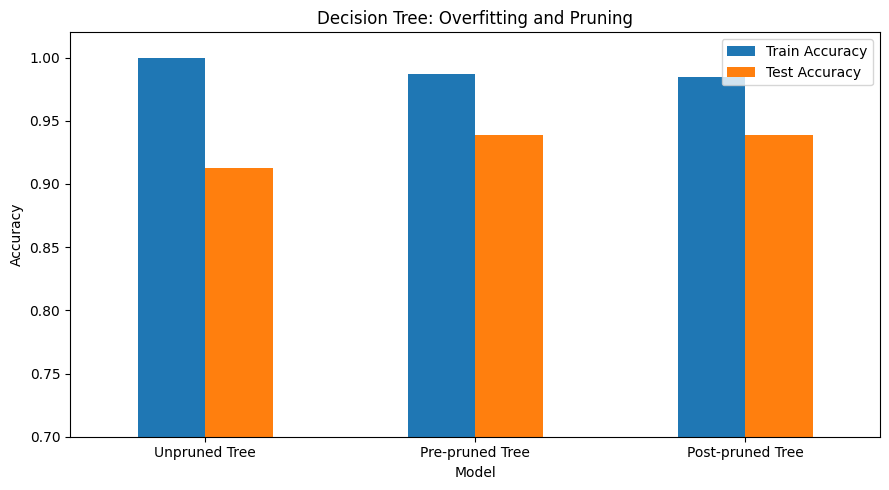

In [27]:
# Pruning

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score

# 1. Load dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define models
models = {
    "Unpruned Tree": DecisionTreeClassifier(
        random_state=42
    ),
    "Pre-pruned Tree": DecisionTreeClassifier(
        max_depth=4,
        random_state=42
    ),
    "Post-pruned Tree": DecisionTreeClassifier(
        ccp_alpha=0.005,
        random_state=42
    )
}

results = []

# 4. Train and evaluate
for name, classifier in models.items():
    model = Pipeline([
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)

    train_accuracy = accuracy_score(
        y_train, train_pred
    )
    test_accuracy = accuracy_score(
        y_test, test_pred
    )

    results.append({
        "Model": name,
        "Train Accuracy": train_accuracy,
        "Test Accuracy": test_accuracy,
        "Accuracy Gap": train_accuracy - test_accuracy,
        "Tree Depth": model.named_steps[
            "classifier"
        ].get_depth(),
        "Leaves": model.named_steps[
            "classifier"
        ].get_n_leaves()
    })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))

# 5. Visualize train vs test accuracy
results_df.plot(
    x="Model",
    y=["Train Accuracy", "Test Accuracy"],
    kind="bar",
    ylim=(0.7, 1.02),
    figsize=(9, 5)
)

plt.title("Decision Tree: Overfitting and Pruning")
plt.ylabel("Accuracy")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [28]:
# Decision Tree Regressor

import pandas as pd

from sklearn.datasets import load_diabetes
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate
)
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# 1. Load dataset
data = load_diabetes(as_frame=True)
X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 3. Define regression criteria
criteria = ["squared_error", "absolute_error"]

# 4. Define cross-validation
cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

# 5. Train and evaluate
for criterion in criteria:

    model = Pipeline([
        ("regressor", DecisionTreeRegressor(
            criterion=criterion,
            max_depth=4,
            random_state=42
        ))
    ])

    # Train
    model.fit(X_train, y_train)

    # Predict
    y_pred = model.predict(X_test)

    # Test metrics
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    rmse = mse ** 0.5
    r2 = r2_score(y_test, y_pred)

    # Cross-validation
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "mse": "neg_mean_squared_error",
            "r2": "r2"
        }
    )

    results.append({
        "Criterion": criterion,
        "Test MAE": mae,
        "Test MSE": mse,
        "Test RMSE": rmse,
        "Test R2": r2,
        "CV MAE": -cv_scores["test_mae"].mean(),
        "CV MSE": -cv_scores["test_mse"].mean(),
        "CV R2": cv_scores["test_r2"].mean()
    })

# 6. Display results
results_df = pd.DataFrame(results)

print("Decision Tree Regressor Results:")
print(results_df.round(4).to_string(index=False))


Decision Tree Regressor Results:
     Criterion  Test MAE  Test MSE  Test RMSE  Test R2  CV MAE    CV MSE  CV R2
 squared_error   47.0454 3568.9653    59.7408   0.3264 54.3675 4618.5371 0.2212
absolute_error   48.4045 4103.9270    64.0619   0.2254 53.0536 4519.1990 0.2216


In [29]:
# Linear Regression

import pandas as pd

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    mean_squared_error,
    r2_score
)

# 1. Load dataset
data = load_diabetes(as_frame=True)
X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# 3. Create pipeline
model = Pipeline([
    ("regressor", LinearRegression())
])

# 4. Train model
model.fit(X_train, y_train)

# 5. Predict
y_pred = model.predict(X_test)

# 6. Evaluate model
mse = mean_squared_error(y_test, y_pred)
rmse = mse ** 0.5
r2 = r2_score(y_test, y_pred)

# 7. Display results
print("Linear Regression Performance")
print("-----------------------------")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")

# 8. Compare actual and predicted values
comparison = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred
})

print("\nActual vs Predicted:")
print(comparison.head(10).round(2))


Linear Regression Performance
-----------------------------
MSE  : 2900.1936
RMSE : 53.8534
R2   : 0.4526

Actual vs Predicted:
   Actual  Predicted
0   219.0     139.55
1    70.0     179.52
2   202.0     134.04
3   230.0     291.42
4   111.0     123.79
5    84.0      92.17
6   242.0     258.23
7   272.0     181.34
8    94.0      90.22
9    96.0     108.63



Ridge (L2)
Confusion Matrix:
[[41  1]
 [ 1 71]]

Classification Report:
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114


Lasso (L1)
Confusion Matrix:
[[41  1]
 [ 0 72]]

Classification Report:
              precision    recall  f1-score   support

   malignant       1.00      0.98      0.99        42
      benign       0.99      1.00      0.99        72

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114


Performance Comparison:
     Model  Test Accuracy  Test Precision  Test Recall  Test F1  CV Accuracy  CV Precision  CV Recall  CV F1
Ridge (L2)         0.9825          0.9861       0.9861   0.9861   

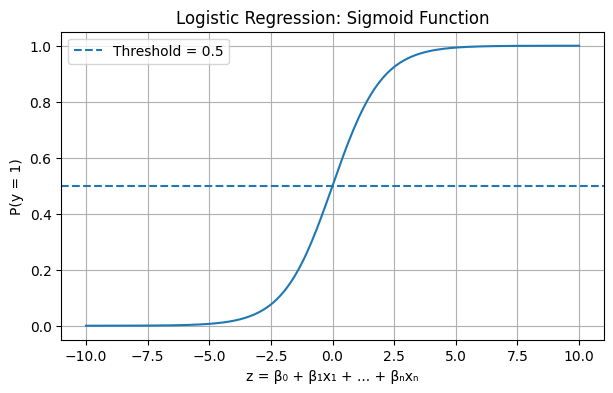

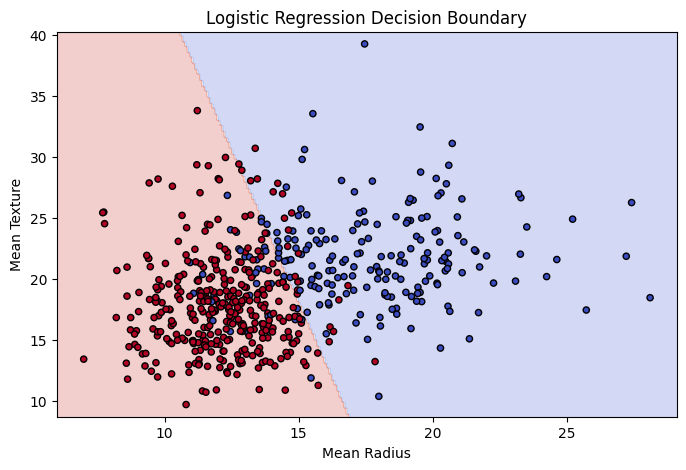

In [30]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# 1. Load dataset
data = load_breast_cancer(as_frame=True)
X = data.data
y = data.target

# 2. Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 3. Define cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 4. Define regularization methods
models = {
    "Ridge (L2)": LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=5000,
        random_state=42
    ),
    "Lasso (L1)": LogisticRegression(
        penalty="l1",
        solver="liblinear",
        C=1.0,
        max_iter=5000,
        random_state=42
    )
}

results = []

# 5. Train and evaluate
for name, classifier in models.items():

    model = Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", classifier)
    ])

    model.fit(X_train, y_train)

    # Predictions
    y_pred = model.predict(X_test)

    # Performance metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    # Cross-validation on training data
    cv_scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=["accuracy", "precision", "recall", "f1"]
    )

    results.append({
        "Model": name,
        "Test Accuracy": accuracy,
        "Test Precision": precision,
        "Test Recall": recall,
        "Test F1": f1,
        "CV Accuracy": cv_scores["test_accuracy"].mean(),
        "CV Precision": cv_scores["test_precision"].mean(),
        "CV Recall": cv_scores["test_recall"].mean(),
        "CV F1": cv_scores["test_f1"].mean()
    })

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_test, y_pred))

    print("\nClassification Report:")
    print(classification_report(
        y_test, y_pred,
        target_names=data.target_names,
        zero_division=0
    ))

# 6. Compare models
results_df = pd.DataFrame(results)

print("\nPerformance Comparison:")
print(results_df.round(4).to_string(index=False))

# 7. Sigmoid function demonstration
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

z = np.linspace(-10, 10, 200)
probabilities = sigmoid(z)

plt.figure(figsize=(7, 4))
plt.plot(z, probabilities)
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.xlabel("z = β₀ + β₁x₁ + ... + βₙxₙ")
plt.ylabel("P(y = 1)")
plt.title("Logistic Regression: Sigmoid Function")
plt.legend()
plt.grid(True)
plt.show()

# 8. Decision boundary using two features
# Use two features to visualize the boundary
X_two = X[["mean radius", "mean texture"]]

X_train2, X_test2, y_train2, y_test2 = train_test_split(
    X_two, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

boundary_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        penalty="l2",
        C=1.0,
        max_iter=5000
    ))
])

boundary_model.fit(X_train2, y_train2)

x_min, x_max = X_two.iloc[:, 0].min() - 1, X_two.iloc[:, 0].max() + 1
y_min, y_max = X_two.iloc[:, 1].min() - 1, X_two.iloc[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = pd.DataFrame({
    "mean radius": xx.ravel(),
    "mean texture": yy.ravel()
})

Z = boundary_model.predict(grid).reshape(xx.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
plt.scatter(
    X_two["mean radius"],
    X_two["mean texture"],
    c=y,
    cmap="coolwarm",
    edgecolors="black",
    s=20
)
plt.xlabel("Mean Radius")
plt.ylabel("Mean Texture")
plt.title("Logistic Regression Decision Boundary")
plt.show()
